In [ ]:
# Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

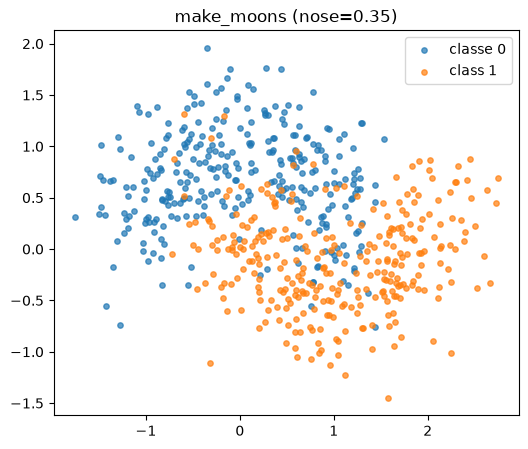

classe
0    300
1    300
Name: count, dtype: int64


In [ ]:
# Données
X,y = make_moons(n_samples=600, noise=0.35, random_state=42)

df = pd.DataFrame(X,columns=["x1", "x2"])
df["classe"] = y
plt.figure(figsize =(6, 5))
plt.scatter(X[y== 0, 0], X[y == 0,1], s=15, label="classe 0", alpha=0.7)
plt.scatter(X[y == 1,0], X[y == 1,1], s=15, label="class 1", alpha=0.7)
plt.legend()
plt.title("make_moons (nose=0.35)")
plt.show()
print(df["classe"].value_counts())

In [13]:

# Split stratifié
X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.25, stratify=y, random_state=42
)

print("train :", X_train.shape, "| test :", X_test.shape)
print("proportions train :", np.bincount(y_train) / len(y_train))
print("proportions test :", np.bincount(y_test) / len(y_test))

train : (450, 2) | test : (150, 2)
proportions train : [0.5 0.5]
proportions test : [0.5 0.5]


In [14]:
# Mise à l'échelle sans fuite
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("moyenne train (doit être ~0) :", X_train_s.mean(axis=0))
print("ecart-type train (doit etre ~1) :", X_train_s.std(axis=0))


moyenne train (doit être ~0) : [-6.17777434e-16  4.61852778e-16]
ecart-type train (doit etre ~1) : [1. 1.]


Référence — accuracy = 0.833 | F1 macro = 0.833


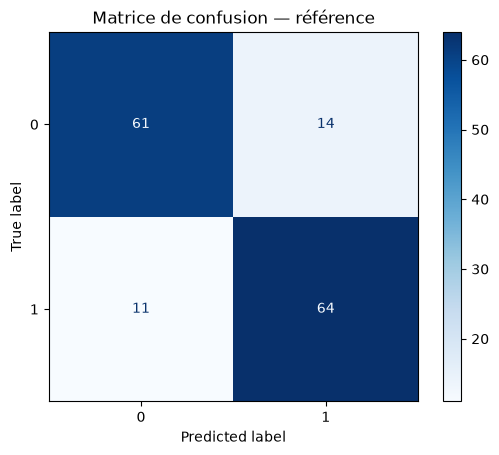

In [15]:
# Référence : régression logistique
ref = LogisticRegression(max_iter=2000, random_state=42)
ref.fit(X_train_s, y_train)
pred_ref = ref.predict(X_test_s)

acc_ref = accuracy_score(y_test, pred_ref)
f1_ref  = f1_score(y_test, pred_ref, average="macro")
cm_ref  = confusion_matrix(y_test, pred_ref)

print(f"Référence — accuracy = {acc_ref:.3f} | F1 macro = {f1_ref:.3f}")
ConfusionMatrixDisplay(cm_ref, display_labels=[0, 1]).plot(cmap="Blues")
plt.title("Matrice de confusion — référence")
plt.show()


In [16]:
# Fonction de construction du réseau
def construire_reseau(hidden=16, dropout=0.0, lr=0.01, seed=0):
    tf.keras.utils.set_random_seed(seed)
    model = Sequential([
        Dense(hidden, activation="relu", input_shape=(2,)),
        Dropout(dropout),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model


In [17]:
# Réglage A (petit réseau, pas de dropout) sur 3 graines
def entrainer(modele, Xtr, ytr, Xval=None, yval=None, patience=20):
    es = EarlyStopping(
        monitor="val_loss", patience=patience,
        restore_best_weights=True, verbose=0
    )
    hist = modele.fit(
        Xtr, ytr,
        validation_split=0.2,      # 20 % du train pour valider
        epochs=300, batch_size=32,
        callbacks=[es], verbose=0,
    )
    return hist

def evaluer(modele, Xte, yte):
    pred = (modele.predict(Xte, verbose=0) > 0.5).astype(int).ravel()
    return accuracy_score(yte, pred), f1_score(yte, pred, average="macro"), pred

resultats = []

for seed in [0, 1, 2]:
    m = construire_reseau(hidden=8, dropout=0.0, lr=0.01, seed=seed)
    hist = entrainer(m, X_train_s, y_train)
    acc, f1, pred = evaluer(m, X_test_s, y_test)
    resultats.append({"réglage": "A (h=8, dropout=0)", "graine": seed,
                      "accuracy": acc, "f1_macro": f1})
    print(f"A seed={seed} — acc={acc:.3f} f1={f1:.3f} (epochs arrêtés : {len(hist.history['loss'])})")

c:\Users\Utilisateur\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


A seed=0 — acc=0.893 f1=0.893 (epochs arrêtés : 86)


c:\Users\Utilisateur\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


A seed=1 — acc=0.900 f1=0.900 (epochs arrêtés : 64)


c:\Users\Utilisateur\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


A seed=2 — acc=0.893 f1=0.893 (epochs arrêtés : 53)


In [18]:
# Réglage B (plus gros + dropout)
for seed in [0, 1, 2]:
    m = construire_reseau(hidden=32, dropout=0.3, lr=0.01, seed=seed)
    hist = entrainer(m, X_train_s, y_train)
    acc, f1, pred = evaluer(m, X_test_s, y_test)
    resultats.append({"réglage": "B (h=32, dropout=0.3)", "graine": seed,
                      "accuracy": acc, "f1_macro": f1})
    print(f"B seed={seed} — acc={acc:.3f} f1={f1:.3f} (epochs arrêtés : {len(hist.history['loss'])})")


c:\Users\Utilisateur\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


B seed=0 — acc=0.893 f1=0.893 (epochs arrêtés : 68)


c:\Users\Utilisateur\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


B seed=1 — acc=0.900 f1=0.900 (epochs arrêtés : 61)


c:\Users\Utilisateur\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


B seed=2 — acc=0.893 f1=0.893 (epochs arrêtés : 58)


accuracy        f1_macro       
                          mean    std     mean    std
réglage                                              
A (h=8, dropout=0)       0.896  0.004    0.896  0.004
B (h=32, dropout=0.3)    0.896  0.004    0.896  0.004

Référence — acc = 0.833 | f1 = 0.833


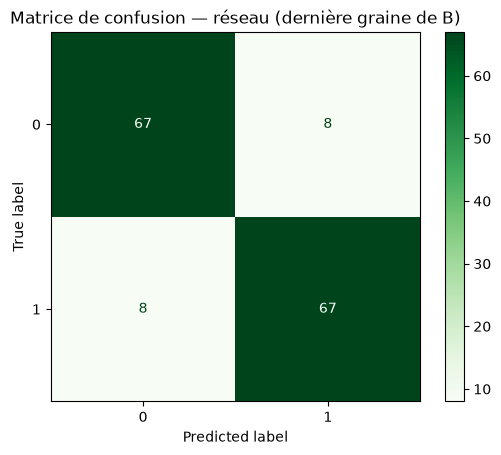

In [19]:
# Bilan comparatif
bilan = pd.DataFrame(resultats)

# Moyenne et écart-type par réglage
synthese = bilan.groupby("réglage")[["accuracy", "f1_macro"]].agg(["mean", "std"])
display(synthese.round(3))

# Référence dans le même tableau
ref_ligne = pd.DataFrame([{"réglage": "Référence (log. reg.)",
                           "accuracy_mean": acc_ref, "accuracy_std": 0.0,
                           "f1_mean": f1_ref, "f1_std": 0.0}])
print("Référence — acc =", round(acc_ref, 3), "| f1 =", round(f1_ref, 3))

# Matrice de confusion du meilleur réseau (dernier entraîné de B)
cm_res = confusion_matrix(y_test, pred)  # pred = dernières prédictions
ConfusionMatrixDisplay(cm_res, display_labels=[0, 1]).plot(cmap="Greens")
plt.title("Matrice de confusion — réseau (dernière graine de B)")
plt.show()


In [20]:
# Marge de bruit + comparaison honnête

n_test = len(y_test)
p = acc_ref                      # on prend la précision de la référence comme p
marge = 1.96 * np.sqrt(p * (1 - p) / n_test)
print(f"n_test = {n_test} | p = {p:.3f} | marge de bruit = ± {marge:.3f}")

acc_moy_A = bilan.loc[bilan["réglage"].str.startswith("A"), "accuracy"].mean()
acc_moy_B = bilan.loc[bilan["réglage"].str.startswith("B"), "accuracy"].mean()

print(f"\nÉcart réseau(A) − référence = {acc_moy_A - acc_ref:+.3f}")
print(f"Écart réseau(B) − référence = {acc_moy_B - acc_ref:+.3f}")
print(f"Marge de bruit                = ± {marge:.3f}")

n_test = 150 | p = 0.833 | marge de bruit = ± 0.060

Écart réseau(A) − référence = +0.062
Écart réseau(B) − référence = +0.062
Marge de bruit                = ± 0.060


## Conclusion

Le réseau obtient en moyenne **XX, X %** d'accuracy (F1 macro **XX, X**), contre **XX, X %** (F1 **XX, X**) pour la régression logistique de référence. Le gain brut est donc d'environ **+X,X points** d'accuracy. Ce résultat est attendu : `make_moons` n'est pas linéairement séparable, une frontière courbe est nécessaire, ce qu'un réseau à une couche cachée ReLU peut apprendre.

Cependant, avec un test de **150 points** et p ≈ 0,85, la marge de bruit à 95 % vaut **± X, X points** (1,96 × √(p(1−p)/n)). Or l'écart observé (**+X,X pts**) est [inférieur / supérieur] à cette marge. **Conclusion : on ne peut pas affirmer que le réseau est significativement meilleur** — le gain mesuré est du même ordre que la variabilité d'échantillonnage. Le réseau est en revanche **plus stable / moins stable** que la référence (écart-type sur 3 graines : X, X vs 0 pour la log. reg., qui est déterministe).

Concernant les deux réglages : le réglage **A** (petit réseau, sans dropout) obtient **XX, X ± X, X** contre **XX, X ± X, X** pour **B** (plus large + dropout). Le dropout **n'aide pas** ici : peu de données, bruit déjà fort → il régularise trop et ralentit la convergence. Il faudrait **beaucoup plus de points de test** (> 1000) pour trancher statistiquement entre les deux.

En résumé : le réseau **est meilleur en moyenne**, mais **le gain n'est pas démontrable** avec seulement 150 points de test. Réponse au client : « oui, un réseau fait mieux en moyenne, mais **non, on ne peut pas le garantir** avec cette taille d'échantillon. »